In [3]:
from openfermion import FermionOperator, QubitOperator, jordan_wigner, lambda_norm, hermitian_conjugated
from openfermion import hermitian_conjugated, normal_ordered, get_sparse_operator
import matplotlib.pyplot as plt

In [4]:
# a b a b a b
state = FermionOperator('0^ 1^')

In [5]:
T = FermionOperator('1 2^') - FermionOperator('2 1^') # must be Hermitian


In [6]:
def is_antihermitian(op):
    hermitian_part = normal_ordered(op + hermitian_conjugated(op))
    return len(hermitian_part.terms) == 0


print('is antihermitian?')
print('T : ', is_antihermitian(T))

is antihermitian?
T :  True


In [7]:
t_qubit = jordan_wigner(T)
print(t_qubit)


0.5j [X1 Y2] +
-0.5j [Y1 X2]


In [8]:
from scipy.sparse.linalg import expm, expm_multiply

vec = get_sparse_operator(state, n_qubits=3)
for op in t_qubit.get_operators():
    sparse_op = get_sparse_operator(op)
    vec = expm_multiply(sparse_op, vec)

In [9]:
vec_ini = get_sparse_operator(state, n_qubits=3)
print((vec_ini.T.conj() @ vec)[0, 0])


(0.5403023058681397+0j)


In [10]:
from scipy.sparse.linalg import expm, expm_multiply

def build_ucc_operator(a):
    vec = get_sparse_operator(state, n_qubits=3)
    sparse_op = get_sparse_operator(a * t_qubit)
    vec = expm_multiply(sparse_op, vec)
    return vec

In [11]:
def build_ucc_operator_trotter(a):
    vec = get_sparse_operator(state, n_qubits=3)
    for op in (a*t_qubit).get_operators():
        sparse_op = get_sparse_operator(op)
        vec = expm_multiply(sparse_op, vec)
    return vec

In [12]:
state_ref1 = FermionOperator('0^ 1^')
state_ref2 = FermionOperator('0^ 2^')

sparse_ref1 = get_sparse_operator(state_ref1, n_qubits=3)
sparse_ref2 = get_sparse_operator(state_ref2, n_qubits=3)

(-1.0, 1.0)

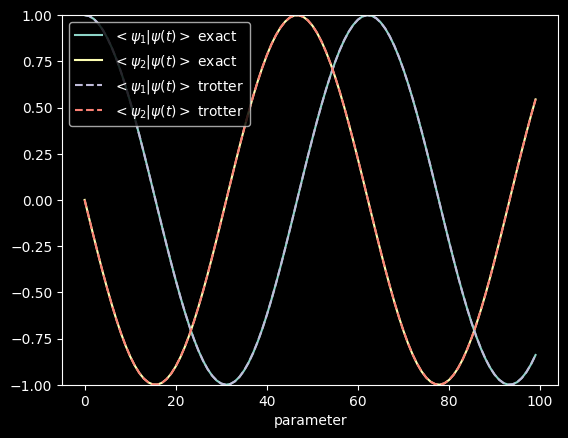

In [13]:
exact_1 = []
exact_2 = []
trotter_1 = []
trotter_2 = []
import numpy as np
for a in np.linspace(0, 10, 100):

    sparse_state = build_ucc_operator(a)

    exact_1.append((sparse_ref1.T.conj() @ sparse_state)[0, 0].real)
    exact_2.append((sparse_ref2.T.conj() @ sparse_state)[0, 0].real)

    sparse_state = build_ucc_operator_trotter(a)

    trotter_1.append((sparse_ref1.T.conj() @ sparse_state)[0, 0].real)
    trotter_2.append((sparse_ref2.T.conj() @ sparse_state)[0, 0].real)

plt.plot(exact_1, label='$<\psi_1 | \psi(t)>$ exact')
plt.plot(exact_2, label='$<\psi_2 | \psi(t)>$ exact')

plt.plot(trotter_1, '--', label='$<\psi_1 | \psi(t)>$ trotter')
plt.plot(trotter_2, '--', label='$<\psi_2 | \psi(t)>$ trotter')
plt.legend()
plt.xlabel('parameter')
plt.ylim(-1, 1)

Define Hamiltonian

In [14]:
Hh = 0.5 * FermionOperator('1^ 1')
ha_qubit = jordan_wigner(Hh)
Hh_sparse = get_sparse_operator(ha_qubit, n_qubits=3)

(0.0, 1.0)

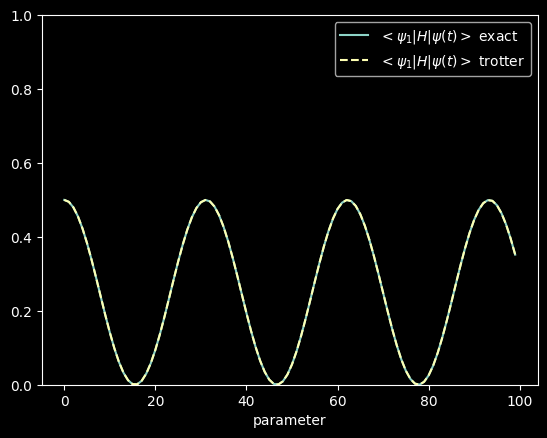

In [15]:
exact = []
trotter = []
import numpy as np
for p in np.linspace(0, 10, 100):

    sparse_state = build_ucc_operator(p)
    exact.append((sparse_state.T.conj() @ Hh_sparse @ sparse_state)[0, 0].real)

    sparse_state = build_ucc_operator_trotter(p)
    trotter.append((sparse_state.T.conj() @ Hh_sparse @  sparse_state)[0, 0].real)

plt.plot(exact, label='$<\psi_1 | H | \psi(t)>$ exact')
plt.plot(trotter, '--', label='$<\psi_1 | H | \psi(t)>$ trotter')
plt.legend()
plt.xlabel('parameter')
plt.ylim(0, 1)

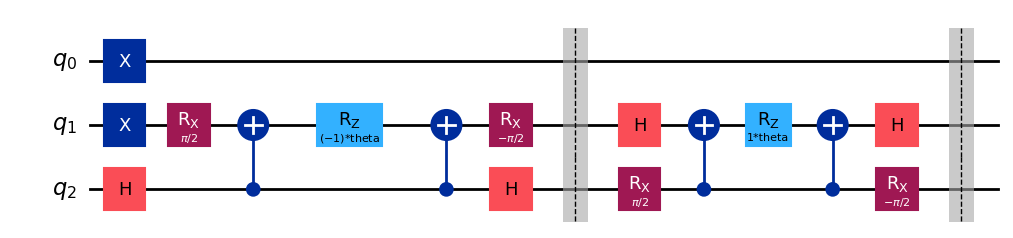

In [16]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc = QuantumCircuit(3)

# exact mapping
#print('====')
#print(jordan_wigner(state))
#print('----')

# reference state
qc.x(0)
qc.x(1)

i_op = 0
for op, coef in t_qubit.terms.items():

    for qubit, pauli in op:
        if pauli == 'X':
            qc.h(qubit)
        elif pauli == 'Y':
            qc.rx(np.pi / 2, [qubit])

    for qubit, pauli in op[1:]:
        qc.cx(qubit, op[0][0])

    if len(op) > 0:
        qc.rz(2*theta * coef.imag, op[0][0])

    for qubit, pauli in reversed(op[1:]):
        qc.cx(qubit, op[0][0])

    for qubit, pauli in op:
        if pauli == 'X':
            qc.h(qubit)
        elif pauli == 'Y':
            qc.rx(np.pi / 2, [qubit])

    qc.barrier()

qc.draw('mpl')

In [17]:
from qiskit.primitives import StatevectorSampler

def cost_function(params):
    energy = 0.0
    for op, coeff in ha_qubit.terms.items():

        # setup circuit
        qc_bound = qc.assign_parameters(params)
        qc_meas = qc_bound.copy()

        # set measurement basis
        for qi, pauli in op:
            if pauli == "X":
                qc_meas.h(qi)
            if pauli == "Y":
                # qc_meas.rx(-np.pi / 2, qi)
                qc_meas.sdg(qi)
                qc_meas.h(qi)

        # add mesure
        qc_meas.measure_all()

        # Sample
        sampler = StatevectorSampler()

        result = sampler.run([qc_meas], shots=1000).result()
        counts = result[0].data.meas.get_counts()

        shots = sum(counts.values())

        # compute expected value
        for bitstring, count in counts.items():

            parity = 1
            for qi, pauli in op:
                if bitstring[::-1][qi] == "1":
                    parity *= -1

            energy += parity * count / shots * coeff

    return energy.real

(0.0, 1.0)

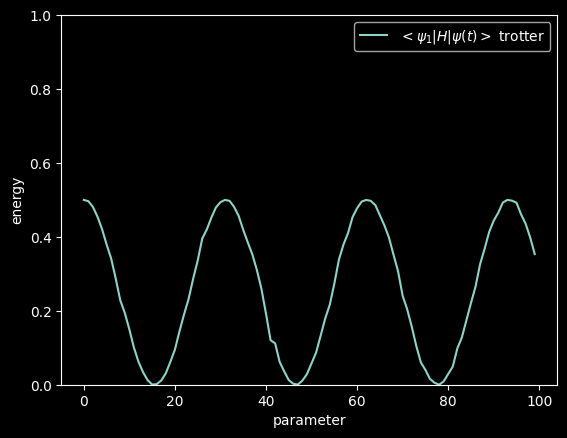

In [18]:
trotter = []
import numpy as np
for t in np.linspace(0, 10, 100):
    energy = cost_function([t])
    trotter.append(energy)

plt.plot(trotter, label='$<\psi_1 | H | \psi(t)>$ trotter')
plt.legend()
plt.xlabel('parameter')
plt.ylabel('energy')

plt.ylim(0, 1)